In [56]:
import re
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [57]:
INPUT_FILE   = "AE_SFRC_3.txt"
OUTPUT_CSV   = "AE_SFRC3_classified.csv"
OUTPUT_XLSX  = "AE_SFRC3_classified.xlsx"
OUTPUT_PLOT  = "crack_classification_RA_AF.png"

AMP_THRESHOLD = 35        # dB  — machine detection threshold (hardware-set)
IQR_K         = 1.5       # Tukey multiplier for IQR outlier bounds (standard = 1.5)
GMM_N_INIT    = 10        # how many random restarts for GMM EM algorithm
GMM_SEED      = 42        # random seed for reproducibility
SVM_C         = 1.0       # SVM regularisation (soft-margin strength)

## STEP 1 — PARSE RAW .TXT FILE INTO A DATAFRAME

In [58]:
hit_rows = []
current_group = {}
group_id = 0

with open(INPUT_FILE, "r") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue

        if line.startswith("Gp#"):
            group_id += 1

            # Extract source location
            loc = re.search(
                r"x\s+y\s+z\s+=\s+([\-\d.]+)\s+([\-\d.]+)\s+([\-\d.]+)", line)
            # Extract quality
            q   = re.search(r"q\s+=\s+([\d.]+)", line)
            # Extract source amplitude
            amp = re.search(r"Src\s+Amplitude\s+=\s+([\d.]+)", line)

            current_group = {
                "group_id" : group_id,
                "src_x"    : float(loc.group(1)) if loc else None,
                "src_y"    : float(loc.group(2)) if loc else None,
                "src_z"    : float(loc.group(3)) if loc else None,
                "quality"  : float(q.group(1))   if q   else None,
                "src_amp"  : float(amp.group(1)) if amp else None,
            }

        else:
            parts = line.split()
            if len(parts) >= 17:
                try:
                    row = {
                        **current_group,          # inherit Gp# metadata
                        "time"      : float(parts[0]),
                        "ch"        : int(parts[4]),
                        "rise"      : int(parts[5]),   # µs
                        "counts"    : int(parts[6]),
                        "energy"    : int(parts[7]),   # eu (energy units)
                        "duration"  : int(parts[8]),   # µs
                        "amp"       : int(parts[9]),   # dB
                        "avg_freq"  : int(parts[10]),  # kHz (hardware calculation)
                        "rms"       : float(parts[11]),
                        "asl"       : int(parts[12]),  # dB
                        "pcnts"     : int(parts[13]),
                        "thr"       : int(parts[14]),  # dB
                        "sig_str"   : float(parts[15]),
                        "abs_energy": float(parts[16]),# aJ (attoJoules)
                    }
                    hit_rows.append(row)
                except Exception:
                    pass                         

df_raw = pd.DataFrame(hit_rows)
print(f"  Total hit rows parsed  : {len(df_raw):,}")
print(f"  Total Gp# events found : {df_raw['group_id'].nunique():,}")
df_raw.head()

  Total hit rows parsed  : 18,141
  Total Gp# events found : 4,068


,group_id,src_x,src_y,src_z,quality,src_amp,time,ch,rise,counts,energy,duration,amp,avg_freq,rms,asl,pcnts,thr,sig_str,abs_energy
0,1,87.90,48.74,317.9,1.0,35.0,16.027975,1,2,2,0,127,35,16,0.0,19,1,35,2500.0,8.51
1,1,87.90,48.74,317.9,1.0,35.0,16.027978,5,35,7,2,684,40,10,0.0,20,2,35,15000.0,63.00
2,1,87.90,48.74,317.9,1.0,35.0,16.027983,6,1,4,1,374,38,11,0.0,21,2,35,7050.0,24.40
3,1,87.90,48.74,317.9,1.0,35.0,16.027997,4,2,1,0,80,36,13,0.0,21,1,35,1300.0,4.66
4,2,55.34,55.59,324.3,1.0,48.0,16.482348,5,71,24,6,1354,48,18,0.0,21,5,35,39600.0,234.00


## STEP 2 — FILTERING

In [59]:
df_filtered = df_raw[
    (df_raw["amp"] >= AMP_THRESHOLD) &
    (df_raw["abs_energy"] >  0) &
    (df_raw["src_x"]>=0) &
    (df_raw["src_y"]>=0) &
    (df_raw["src_z"]>=0) &
    (df_raw['duration'] > 0)
]
print(f"  Events after filter : {df_filtered['group_id'].nunique():,}")
print(f"  Hits   after filter : {len(df_filtered):,}")

  Events after filter : 3,860
  Hits   after filter : 16,971


## STEP 3 — ONE ROW PER EVENT (max abs_energy channel)

In [60]:
df_events = (
    df_filtered
    .sort_values("abs_energy", ascending=False)
    .groupby("group_id", as_index=False)
    .first()                              # first row after sort = highest abs_energy
)
print(f"  One row per Group  : {len(df_events):,}")
df_events.head()

  One row per Group  : 3,860


,group_id,src_x,src_y,src_z,quality,src_amp,time,ch,rise,counts,energy,duration,amp,avg_freq,rms,asl,pcnts,thr,sig_str,abs_energy
0,1,87.90,48.74,317.9,1.0,35.0,16.027978,5,35,7,2,684,40,10,0.0,20,2,35,15000.0,63.0
1,2,55.34,55.59,324.3,1.0,48.0,16.482348,5,71,24,6,1354,48,18,0.0,21,5,35,39600.0,234.0
2,3,38.58,97.64,313.9,1.0,41.0,19.764904,5,74,21,5,1377,47,15,0.0,20,5,35,36400.0,195.0
3,4,82.54,170.40,344.7,1.0,36.0,19.806100,5,51,11,2,844,44,13,0.0,21,3,35,18200.0,78.5
4,5,23.10,202.60,356.2,1.0,45.0,26.278627,5,2,28,6,1301,49,22,0.0,21,1,35,40300.0,266.0


## STEP 4 — COMPUTE RA AND AF

In [61]:
df_events["RA"] = df_events["rise"] / df_events["amp"]
df_events["AF"] = (df_events["counts"] / df_events["duration"]) * 1000

print("  RA and AF distribution:")
print(df_events[["RA", "AF"]].describe().round(3).to_string())


  RA and AF distribution:
             RA        AF
count  3860.000  3860.000
mean      7.248    35.624
std      22.012    13.153
min       0.019     4.526
25%       0.857    27.228
50%       1.667    34.191
75%       4.000    41.856
max     503.379   144.262


## STEP 5 — IQR OUTLIER REMOVAL (RA upper + AF upper only)

In [62]:
def iqr_upper(series, k=IQR_K):
    Q1  = series.quantile(0.25)
    Q3  = series.quantile(0.75)
    IQR = Q3 - Q1
    return Q3 + k * IQR

ra_upper = iqr_upper(df_events["RA"])
af_upper = iqr_upper(df_events["AF"])

print(f"  IQR upper bound — RA   : {ra_upper:.3f} µs/V  "
      f"(events above this have impossible rise times = noise)")
print(f"  IQR upper bound — AF   : {af_upper:.3f} kHz   "
      f"(events above this have anomalous frequencies  = noise)")

before = len(df_events)
df_clean = df_events[
    (df_events["RA"] <= ra_upper) &
    (df_events["AF"] <= af_upper)
].copy()

removed = before - len(df_clean)

print(f"  Events removed : {removed} ({100*removed/before:.1f}%)")
print(f"  Events remaining : {len(df_clean):,}")

print(f"  RA range after filter : [{df_clean['RA'].min():.3f}, {df_clean['RA'].max():.3f}] µs/V")
print(f"  AF range after filter : [{df_clean['AF'].min():.3f}, {df_clean['AF'].max():.3f}] kHz")

  IQR upper bound — RA   : 8.714 µs/V  (events above this have impossible rise times = noise)
  IQR upper bound — AF   : 63.799 kHz   (events above this have anomalous frequencies  = noise)
  Events removed : 669 (17.3%)
  Events remaining : 3,191
  RA range after filter : [0.019, 8.698] µs/V
  AF range after filter : [4.526, 63.764] kHz


## STEP 6 — GMM CLUSTERING (K = 2)

In [63]:
X_raw    = df_clean[["RA", "AF"]].values    # original units — used for SVM
print(X_raw)
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)       # standardized — used for GMM

gmm = GaussianMixture(
    n_components     = 2,
    covariance_type  = "full",
    random_state     = GMM_SEED,
    n_init           = GMM_N_INIT
)
gmm_labels            = gmm.fit_predict(X_scaled)
df_clean["gmm_label"] = gmm_labels

# Name clusters by physical convention
cluster_means  = df_clean.groupby("gmm_label")[["RA", "AF"]].mean()
tensile_id     = (cluster_means["AF"] / cluster_means["RA"]).idxmax()
shear_id       = 1 - tensile_id

df_clean["gmm_crack_type"] = df_clean["gmm_label"].map(
    {tensile_id: "Tensile", shear_id: "Shear"})

print(f"  GMM cluster mean RA and AF:")
for cid, row in cluster_means.iterrows():
    name = "Tensile" if cid == tensile_id else "Shear"
    print(f"    Cluster {cid} → {name:7s} | mean RA={row['RA']:.3f}  mean AF={row['AF']:.3f}")

print(f"\n  GMM event counts:")
for ctype, cnt in df_clean["gmm_crack_type"].value_counts().items():
    print(f"    {ctype:7s} : {cnt:,}")

print(f"\n  GMM log-likelihood (convergence): {gmm.lower_bound_:.4f}")

[[ 0.875      10.23391813]
 [ 1.47916667 17.72525849]
 [ 1.57446809 15.25054466]
 ...
 [ 0.78333333 48.28519856]
 [ 0.22916667 49.09560724]
 [ 3.31914894 31.75965665]]
  GMM cluster mean RA and AF:
    Cluster 0 → Tensile | mean RA=1.028  mean AF=35.181
    Cluster 1 → Shear   | mean RA=4.129  mean AF=33.403

  GMM event counts:
    Tensile : 2,257
    Shear   : 934

  GMM log-likelihood (convergence): -2.5928


## STEP 7 — LINEAR SVM: FIND THE UNIQUE OPTIMAL BOUNDARY LINE

In [64]:
y_train = (df_clean["gmm_crack_type"] == "Tensile").astype(int).values
print(y_train)
svm = SVC(kernel="linear", C=SVM_C)
svm.fit(X_raw, y_train)        # fit on ORIGINAL units (not scaled)

w = svm.coef_[0]               # [w_RA, w_AF]
b = svm.intercept_[0]
m = -w[0] / w[1]               # slope
c = -b / w[1]               # intercept

svm_preds = svm.predict(X_raw)
df_clean["final_type"] = svm_preds
df_clean["final_type"] = df_clean["final_type"].map({1: "Tensile", 0: "Shear"})

agreement  = (df_clean["gmm_crack_type"] == df_clean["final_type"]).mean()
overlap_n  = (df_clean["gmm_crack_type"] != df_clean["final_type"]).sum()

tensile_n  = (df_clean["final_type"] == "Tensile").sum()
shear_n    = (df_clean["final_type"] == "Shear").sum()
tensile_pct= 100 * tensile_n / len(df_clean)
shear_pct  = 100 * shear_n   / len(df_clean)
ts_ratio   = tensile_n / shear_n

print(f"  Boundary line          : AF = {m:.4f} · RA + {c:.4f}")
print(f"  SVM agreement with GMM : {100*agreement:.2f}%")
print(f"  Overlap zone (GMM≠SVM) : {overlap_n} events ({100*overlap_n/len(df_clean):.1f}%) "
      f"← these sit between both clusters (mixed-mode cracking)")
print(f"\n  Final classification:")
print(f"    Tensile : {tensile_n:,}  ({tensile_pct:.1f}%)")
print(f"    Shear   : {shear_n:,}  ({shear_pct:.1f}%)")
print(f"\n  Relative Share T/S = {ts_ratio:.2f}")
print(f"  [Das et al. found 2 < T/S < 10 for SFRC with steel fibers]")
if 2 <= ts_ratio <= 10:
    print(f"  → T/S = {ts_ratio:.2f} is WITHIN the expected range ✓")
else:
    print(f"  → T/S = {ts_ratio:.2f} is OUTSIDE the expected range — review filtering")

[1 1 1 ... 1 1 0]
  Boundary line          : AF = 69.9205 · RA + -125.9607
  SVM agreement with GMM : 99.44%
  Overlap zone (GMM≠SVM) : 18 events (0.6%) ← these sit between both clusters (mixed-mode cracking)

  Final classification:
    Tensile : 2,261  (70.9%)
    Shear   : 930  (29.1%)

  Relative Share T/S = 2.43
  [Das et al. found 2 < T/S < 10 for SFRC with steel fibers]
  → T/S = 2.43 is WITHIN the expected range ✓


## STEP 8 — EVALUATION METRICS

In [65]:
sil = silhouette_score(X_scaled, gmm_labels)
db  = davies_bouldin_score(X_scaled, gmm_labels)
ll  = gmm.lower_bound_

print(f"  Silhouette Score : {sil:.4f}")
if sil >= 0.5:
    sil_interp = "STRONG separation — two clearly distinct groups"
elif sil >= 0.25:
    sil_interp = "MODERATE separation — two groups visible but overlapping (expected for AE)"
else:
    sil_interp = "WEAK separation — significant overlap; boundary line has high uncertainty"
print(f"  Interpretation : {sil_interp}")

print(f"\n  Davies-Bouldin Index   : {db:.4f}  (lower = better, no fixed scale)")
print(f"  GMM Log-likelihood     : {ll:.4f}  (higher = better GMM fit)")
print(f"\n  Note: Silhouette ~0.35–0.45 is typical for AE crack classification")
print(f"  studies due to the physical reality of mixed-mode cracking in SFRC.")

  Silhouette Score : 0.3788
  Interpretation : MODERATE separation — two groups visible but overlapping (expected for AE)

  Davies-Bouldin Index   : 1.1306  (lower = better, no fixed scale)
  GMM Log-likelihood     : -2.5928  (higher = better GMM fit)

  Note: Silhouette ~0.35–0.45 is typical for AE crack classification
  studies due to the physical reality of mixed-mode cracking in SFRC.


# STEP 9 — PLOT

  Saved plot             : crack_classification_RA_AF.png


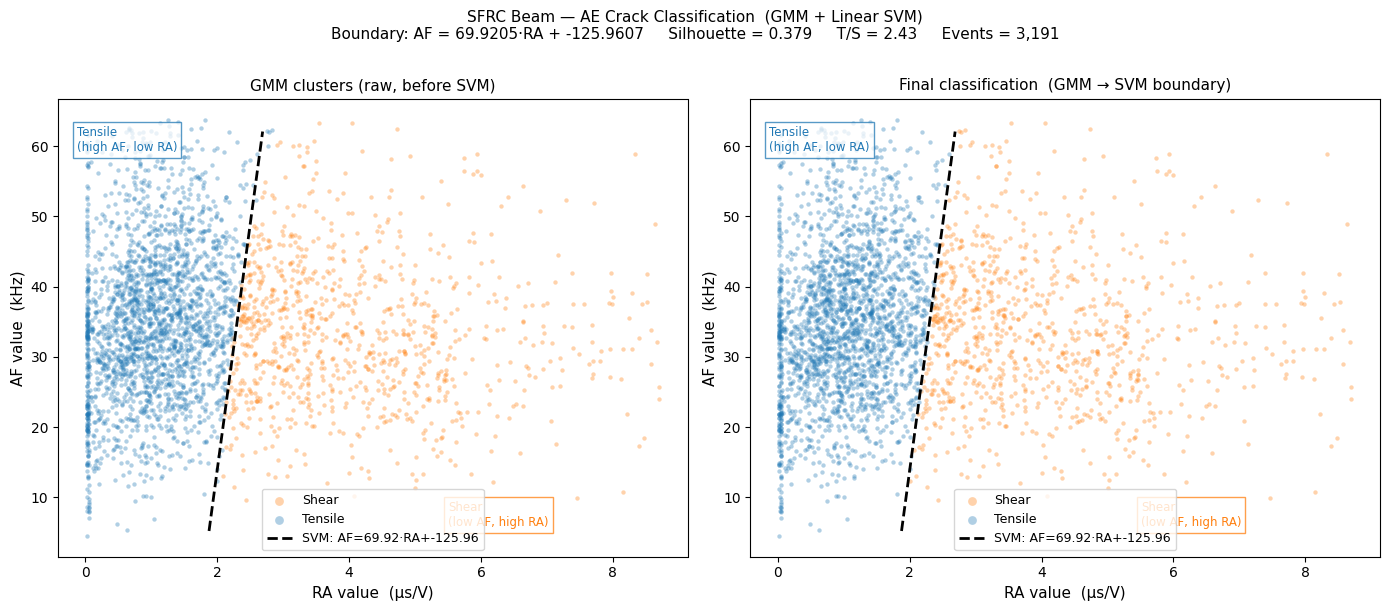

In [66]:
COLORS = {"Tensile": "#1f77b4", "Shear": "#ff7f0e"}    # blue / orange

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Generate the SVM boundary line across the RA axis
ra_line = np.linspace(df_clean["RA"].min(), df_clean["RA"].max(), 300)
af_line = m * ra_line + c
af_min, af_max = df_clean["AF"].min(), df_clean["AF"].max()
mask = (af_line >= af_min) & (af_line <= af_max)

for ax_idx, (col, title) in enumerate([
    ("gmm_crack_type", "GMM clusters (raw, before SVM)"),
    ("final_type",     "Final classification  (GMM → SVM boundary)")
]):
    ax = axes[ax_idx]
    for ctype, grp in df_clean.groupby(col):
        ax.scatter(grp["RA"], grp["AF"],
                   c=COLORS[ctype], label=ctype,
                   alpha=0.35, s=10, linewidths=0)

    ax.plot(ra_line[mask], af_line[mask],
            "k--", lw=2.0, label=f"SVM: AF={m:.2f}·RA+{c:.2f}")

    ax.set_xlabel("RA value  (µs/V)",  fontsize=11)
    ax.set_ylabel("AF value  (kHz)",   fontsize=11)
    ax.set_title(title,                fontsize=11)
    ax.legend(fontsize=9, markerscale=2)

    # Region annotation labels (matching Das et al. figure style)
    ax.text(0.03, 0.94,
            "Tensile\n(high AF, low RA)",
            transform=ax.transAxes, fontsize=8.5, color=COLORS["Tensile"],
            va="top",
            bbox=dict(facecolor="white", edgecolor=COLORS["Tensile"], alpha=0.75, pad=3))
    ax.text(0.62, 0.06,
            "Shear\n(low AF, high RA)",
            transform=ax.transAxes, fontsize=8.5, color=COLORS["Shear"],
            va="bottom",
            bbox=dict(facecolor="white", edgecolor=COLORS["Shear"], alpha=0.75, pad=3))

plt.suptitle(
    f"SFRC Beam — AE Crack Classification  (GMM + Linear SVM)\n"
    f"Boundary: AF = {m:.4f}·RA + {c:.4f}     "
    f"Silhouette = {sil:.3f}     "
    f"T/S = {ts_ratio:.2f}     "
    f"Events = {len(df_clean):,}",
    fontsize=11, y=1.01
)
plt.tight_layout()
plt.savefig(OUTPUT_PLOT, dpi=150, bbox_inches="tight")
print(f"  Saved plot             : {OUTPUT_PLOT}")


## STEP 10 — EXPORT TO CSV AND XLSX

In [67]:
export_cols = [
    "group_id", "time",
    "src_x", "src_y", "src_z", "quality", "src_amp",
    "ch", "rise", "counts", "energy", "duration",
    "amp", "avg_freq", "rms", "asl", "abs_energy",
    "RA", "AF",
    "gmm_crack_type",   # raw GMM label (before SVM fine-tuning)
    "final_type",       # final label after SVM boundary (use this for analysis)
]

df_clean[export_cols].to_csv(OUTPUT_CSV,  index=False)
df_clean[export_cols].to_excel(OUTPUT_XLSX, index=False)
print(f"  Saved CSV              : {OUTPUT_CSV}")
print(f"  Saved XLSX             : {OUTPUT_XLSX}")

  Saved CSV              : AE_SFRC3_classified.csv
  Saved XLSX             : AE_SFRC3_classified.xlsx


## FINAL SUMMARY

In [68]:
print("\n" + "=" * 60)
print("FINAL SUMMARY")
print("=" * 60)
print(f"  Raw hits parsed              : {len(df_raw):>7,}")
print(f"  After threshold+abs_energy   : {df_filtered['group_id'].nunique():>7,}  events")
print(f"  After max abs_energy per Gp# : {len(df_events):>7,}  events")
print(f"  After IQR noise removal      : {len(df_clean):>7,}  events")
print(f"  ── Noise removed (IQR)       : {removed:>7,}  events ({100*removed/before:.1f}%)")
print()
print(f"  GMM + SVM boundary line  :  AF = {m:.4f} · RA + {c:.4f}")
print()
print(f"  Final Tensile events     : {tensile_n:>5,}  ({tensile_pct:.1f}%)")
print(f"  Final Shear   events     : {shear_n:>5,}  ({shear_pct:.1f}%)")
print(f"  Relative Share (T/S)     : {ts_ratio:.2f}")
print()
print(f"  Silhouette Score         : {sil:.4f}")
print(f"  Davies-Bouldin Index     : {db:.4f}")
print()
print(f"  Outputs saved:")
print(f"    {OUTPUT_CSV}")
print(f"    {OUTPUT_XLSX}")
print(f"    {OUTPUT_PLOT}")
print("=" * 60)


FINAL SUMMARY
  Raw hits parsed              :  18,141
  After threshold+abs_energy   :   3,860  events
  After max abs_energy per Gp# :   3,860  events
  After IQR noise removal      :   3,191  events
  ── Noise removed (IQR)       :     669  events (17.3%)

  GMM + SVM boundary line  :  AF = 69.9205 · RA + -125.9607

  Final Tensile events     : 2,261  (70.9%)
  Final Shear   events     :   930  (29.1%)
  Relative Share (T/S)     : 2.43

  Silhouette Score         : 0.3788
  Davies-Bouldin Index     : 1.1306

  Outputs saved:
    AE_SFRC3_classified.csv
    AE_SFRC3_classified.xlsx
    crack_classification_RA_AF.png
